# 08 · Step 4: intensities from the tree, and the synthetic image

Two parts:

* **4a, `tree_intensities.sample`** (no voxels): draw one Gaussian `(mu, sigma)` per label from
  the label tree, for this image's resolution and contrast;
* **4b, `synthesis.apply`**: paint the image from the partial volumes and these Gaussians.

Code: `nxgen/online/tree_intensities.py`, `nxgen/online/synthesis.py`. Config section: `tree`.

In [1]:
from _setup import *
from nxgen.online import tree_intensities as TI, synthesis as SY, partial_volume as PV
from nxgen.online import acquisition as A
from nxgen.core.config import load_config
from nxgen.core.label_space import LabelSpace
from nxgen.core.tree import LabelTree
from nxgen.checks import gaussian_fit_pure
import phantoms

## 1. The sampling model

Per image:

1. **principal colors**: `C[i] ~ U(colors_mu)`, `V[i] ~ U(colors_sigma)`, one per tree color
   (e.g. GM, WM, CSF). This is what makes every image a different "contrast".
2. **top-down over the tree** (breadth-first), with `N(0,1)` draws:

```
level 1   : mu = sum_i w_mu[i] C[i] + wr_mu N(0,1)
            sd = sum_i w_sigma[i] V[i] + wr_sigma N(0,1)
level >= 2: visible     -> mu = mu_parent + wr_mu N(0,1),  sd = sd_parent + wr_sigma N(0,1)
            not visible -> exactly (mu_parent, sd_parent)
sd = max(sd, min_sigma);  'null' nodes (and their subtrees): mu = sd = 0
```

3. every label takes the `(mu, sd)` of its node.

Visibility (notebook 02) uses the **resolution** of the image: with
`tree.resolution = 'acquisition'`, the coarsest spacing of step 0; otherwise a spec (e.g.
`[0.75, 3]`), drawn here. The contrast comes from the acquisition.

In [2]:
toy = phantoms.tree()
ls = LabelSpace.build(toy, {0, 2, 3, 24, 42})
cfg = load_config()['tree']
print(cfg)
p = TI.sample(cfg, np.random.default_rng(0), toy, ls, A.none_params(0.8))
for k, v in p.items():
    print(f'{k:16s} {np.round(v, 2).tolist() if isinstance(v, list) and k not in ("class_names",) else v}')

{'colors_mu': [0.0, 255.0], 'colors_sigma': [0.255, 2.55], 'min_sigma': 0.0, 'intensity_scale': 255.0, 'resolution': 'acquisition'}
colors_mu        [162.43, 68.8, 10.45]
colors_sigma     [0.29, 2.12, 2.35]
resolution_mm    0.8
contrast         None
mu               [0.0, 57.17, 159.31, 6.93, 134.39]
sigma            [0.0, 2.01, 0.31, 1.72, 0.0]
class_of         [0, 1, 2, 3, 4]
class_names      ['background', 'wm', 'gm', 'csf', 'gm_part']
intensity_scale  255.0
noise_seed       191741831


The dict goes into `plan['tree']`:

| key | meaning |
|---|---|
| `colors_mu`, `colors_sigma` | C and V |
| `resolution_mm`, `contrast` | used for visibility |
| `mu`, `sigma` | per label **index** (tree units, e.g. 0-255) |
| `class_of` | generation class of each label index |
| `class_names` | the visible node of each class (`'unassigned'` for labels without a node) |
| `intensity_scale` | the image is divided by it after the synthesis |
| `noise_seed` | seed of the per-voxel noise of 4b |

## 2. Collapsing with resolution

In [3]:
# only the spacing (-> resolution) and the contrast of the acquisition matter here
for res, contrast in [(0.8, None), (2.0, None), (2.0, 'T2')]:
    q = TI.sample(cfg, np.random.default_rng(0), toy, ls, A.none_params(res, contrast))
    gm, part = ls.index[3], ls.index[42]
    print(f'res {res} {contrast}: gm mu {q["mu"][gm]:7.2f}, gm_part mu {q["mu"][part]:7.2f}, '
          f'classes {q["class_names"]}')

res 0.8 None: gm mu  159.31, gm_part mu  134.39, classes ['background', 'wm', 'gm', 'csf', 'gm_part']
res 2.0 None: gm mu  159.31, gm_part mu  159.31, classes ['background', 'wm', 'gm', 'csf']
res 2.0 T2: gm mu  159.31, gm_part mu  134.39, classes ['background', 'wm', 'gm', 'csf', 'gm_part']


* At 0.8 mm `gm_part` (r_max 1 mm) is visible: own Gaussian, own class.
* At 2 mm it collapses: **exactly** the parent's Gaussian, same class.
* With T2, its `r_max` is 2 mm: visible again.
* The visible nodes get the **same values at any resolution** for a fixed seed, because two
  normal numbers are drawn for every node, visible or not. Only the visibility changes.

On NextBrain:

In [4]:
tree = LabelTree.from_json(TREE)
from nxgen.core.io import load_labels
values = set(np.unique(load_labels(SOURCE_MAP)[0]).tolist())
ls_nb = LabelSpace.build(tree, values)
cfg_nb = load_config(CONFIG)['tree']
for res in (0.4, 0.6, 1.0, 3.0):
    q = TI.sample(cfg_nb, np.random.default_rng(0), tree, ls_nb, A.none_params(res))
    print(f'res {res} mm: {len(q["class_names"]):3d} generation classes for {len(ls_nb)} labels, '
          f'{len(set(np.round(q["mu"], 6)))} distinct means')

res 0.4 mm: 263 generation classes for 300 labels, 263 distinct means
res 0.6 mm:  34 generation classes for 300 labels, 34 distinct means
res 1.0 mm:  29 generation classes for 300 labels, 29 distinct means
res 3.0 mm:  15 generation classes for 300 labels, 15 distinct means


## 3. Synthesis

With the top-k partial volumes `(l_i, w_i)` of a voxel (notebook 07):

$$\text{image}(x) = \frac{1}{\text{scale}}\sum_i w_i(x)\,\big(\mu[l_i] + \sigma[l_i]\,\varepsilon_i(x)\big)$$

`ε` is standard normal noise, **one value per voxel and per generation class**: two labels of
the same class in a voxel share the same ε (v2 summed the fractions per class first, which is
equivalent). The noise comes from a generator seeded with `noise_seed`.

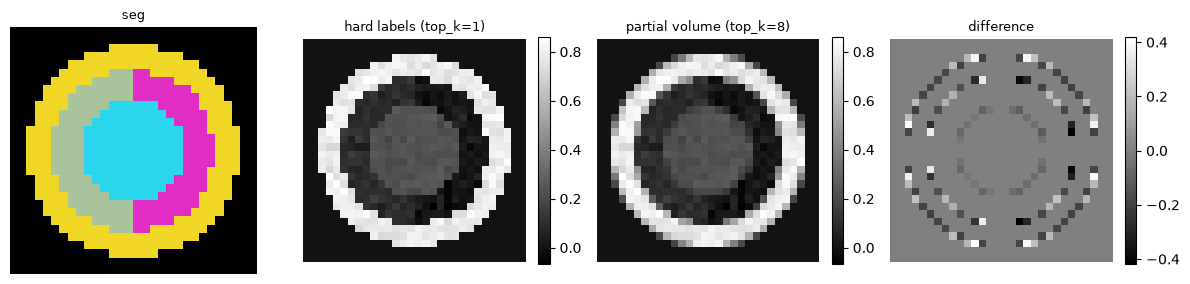

In [5]:
seg = phantoms.sphere_labels((60, 60, 60), scale=2)
lab = ls.lut(int(seg.max()))[torch.as_tensor(seg)]
cfgv = load_config(tree=dict(colors_sigma=[5.0, 10.0]))['tree']
p = TI.sample(cfgv, np.random.default_rng(3), toy, ls, A.none_params(0.8))
pv = PV.apply(lab, 'downsample', factor=2)
hard = PV.apply(lab, 'downsample', factor=2, top_k=1)
img = SY.apply(pv, p)
img_hard = SY.apply(hard, p)
show([pv['seg'], img_hard, img, img - img_hard],
     ['seg', 'hard labels (top_k=1)', 'partial volume (top_k=8)', 'difference'],
     labels=[True, False, False, False], colorbar=True)

Partial volumes only change boundary voxels (right): their intensity is a mix of the neighbours.

## 4. Checking the intensities (the test of the initial proposal)

On **pure** voxels (one label with weight 1), the intensity must follow exactly
`N(mu, sigma) / scale`. Mixed voxels are expected to deviate and are excluded.
`checks.gaussian_fit_pure` computes, per label, the mean, std and a Kolmogorov-Smirnov statistic:

In [6]:
fit = gaussian_fit_pure(img, pv, p)
print(f'{"label":10s} {"n":>6s} {"mean":>8s} {"mu":>8s} {"std":>7s} {"sigma":>7s} {"KS":>6s}')
for i, r in fit.items():
    print(f'{ls.names[i]:10s} {r["n"]:6d} {r["mean"]:8.4f} {r["mu"]:8.4f} {r["std"]:7.4f} {r["sigma"]:7.4f} '
          f'{r["ks"] if r["ks"] is None else round(r["ks"], 4)!s:>6s}')

label           n     mean       mu     std   sigma     KS
background  17000   0.0000   0.0000  0.0000  0.0000   None
wm            720   0.2313   0.2313  0.0202  0.0201 0.0152
gm           1340   0.0900   0.0901  0.0295  0.0303 0.0244
csf          3728   0.7842   0.7843  0.0348  0.0346 0.0132
gm_part      1340   0.0079   0.0073  0.0301  0.0296 0.0217


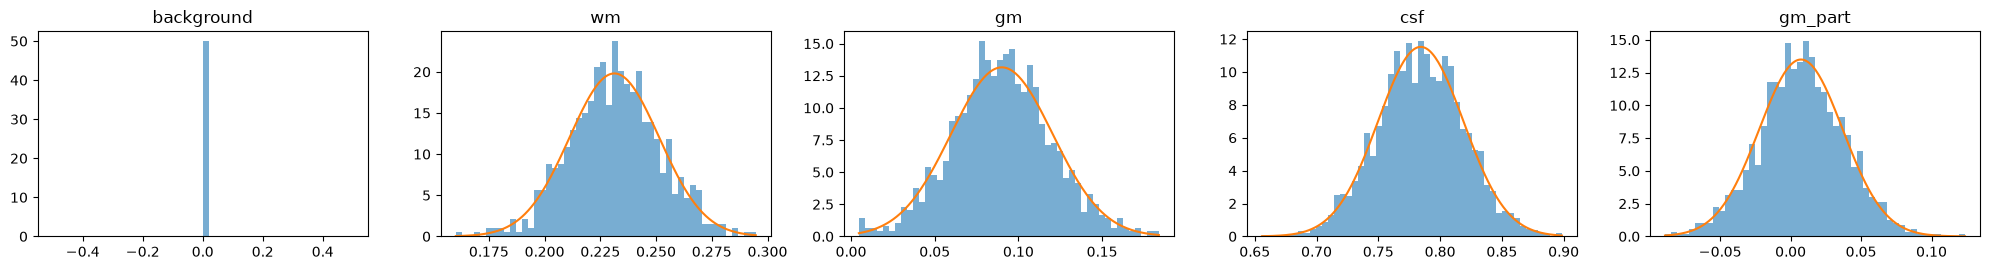

In [7]:
fig, ax = plt.subplots(1, len(fit), figsize=(4 * len(fit), 2.8))
pure = pv['weight'][0] > 1 - 1e-6
for a, (i, r) in zip(np.atleast_1d(ax), fit.items()):
    v = img[pure & (pv['index'][0] == i)].numpy()
    a.hist(v, 50, density=True, alpha=.6)
    if r['sigma'] > 0:
        xs = np.linspace(v.min(), v.max(), 200)
        a.plot(xs, np.exp(-(xs - r['mu']) ** 2 / (2 * r['sigma'] ** 2)) / (r['sigma'] * np.sqrt(2 * np.pi)))
    a.set_title(ls.names[i])
plt.tight_layout(); plt.show()

Background is a `null` node: mu = sigma = 0.

## 5. Same class, same noise

In [8]:
p2 = TI.sample(cfg, np.random.default_rng(0), toy, ls, A.none_params(2.0))
gm, part = ls.index[3], ls.index[42]
two = dict(index=torch.stack([torch.full((6, 6, 6), gm), torch.full((6, 6, 6), part)]).short(),
           weight=torch.full((2, 6, 6, 6), 0.5))
out = SY.apply(two, p2) * p2['intensity_scale']
print('gm and gm_part share a class at 2 mm:', p2['class_of'][gm] == p2['class_of'][part])
print('std of a 50/50 voxel = sigma (one draw), not sigma/sqrt(2):',
      round(float(((out - p2['mu'][gm]) / p2['sigma'][gm]).std()), 3))

gm and gm_part share a class at 2 mm: True
std of a 50/50 voxel = sigma (one draw), not sigma/sqrt(2): 1.065


## 6. On the real template

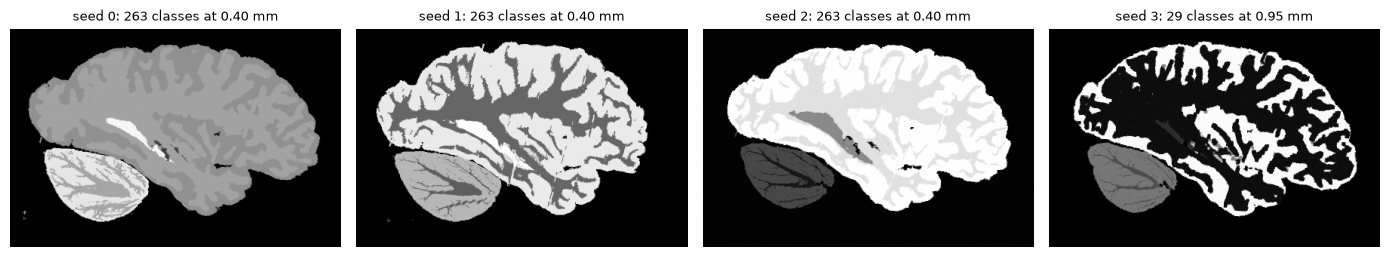

In [9]:
from nxgen import Generator, Recorder
ensure_template()
gen = Generator([TEMPLATE], CONFIG, device=DEVICE)
fig, ax = plt.subplots(1, 4, figsize=(14, 4))
for a, seed in zip(ax, range(4)):
    rec = Recorder(steps=['synthesis'])
    s = gen(seed, recorder=rec)
    a.imshow(mid(rec.steps['synthesis'], 0), cmap='gray', origin='lower')
    a.set_title(f"seed {seed}: {len(s.plan['tree']['class_names'])} classes at "
                f"{s.plan['tree']['resolution_mm']:.2f} mm", fontsize=9)
    a.axis('off')
plt.tight_layout(); plt.show()

Every seed gives a different contrast (C and V), and structures that the resolution cannot
resolve share one intensity.

## 7. Notes

* A std can come out **negative** (`sd_parent + wr_sigma N(0,1)` with a small parent std): it is
  clipped to `min_sigma` (0 by default). In the toy example above, `gm_part` got sigma 0 this way.
  Raise `min_sigma` to keep a minimum texture in every structure.
* `intensity_scale` (255): after the synthesis the image is divided by it, so the bias field and
  noise act on values of order 1 (noise `sigma` 0.05 means 5 % of the colour range).
* `class_of` is what WP4 needs to merge indistinguishable labels in the loss; it is in the plan
  of every image (`sample.class_of`).
* The tree noise is drawn per patch in patch mode (same distribution, different values than the
  same crop of a full volume).